# Baseline evaluation and error analysis

Train the handcrafted-feature reference model, then evaluate its held-out validation predictions. This baseline helps identify dataset/class confusions; it does not replace the image-based CNN. Outputs include aggregate and per-class metrics, a confusion matrix, predictions, and misclassified examples under `dataset/processed/error_analysis/`.


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.train import train_baseline

training_summary = train_baseline(epochs=10)
training_summary


Epoch 1/10: loss=2.6755, accuracy=0.3136
Epoch 2/10: loss=1.4617, accuracy=0.5629
Epoch 3/10: loss=1.1592, accuracy=0.6471
Epoch 4/10: loss=1.0070, accuracy=0.6892
Epoch 5/10: loss=0.9067, accuracy=0.7177
Epoch 6/10: loss=0.8345, accuracy=0.7388
Epoch 7/10: loss=0.7750, accuracy=0.7571
Epoch 8/10: loss=0.7276, accuracy=0.7713
Epoch 9/10: loss=0.6911, accuracy=0.7824
Epoch 10/10: loss=0.6559, accuracy=0.7916
Baseline checkpoint written to C:\Git_projects\Leaf_disease_detector\models\feature_baseline.pt


{'checkpoint': WindowsPath('C:/Git_projects/Leaf_disease_detector/models/feature_baseline.pt'),
 'device': 'cpu',
 'train_images': 70295,
 'validation_images': 17572,
 'classes': 38,
 'history': [{'epoch': 1,
   'loss': 2.675459984785395,
   'accuracy': 0.31363539369798704},
  {'epoch': 2, 'loss': 1.4617207022799954, 'accuracy': 0.5629418877587311},
  {'epoch': 3, 'loss': 1.1591788144630222, 'accuracy': 0.6470588235294118},
  {'epoch': 4, 'loss': 1.0069599854979205, 'accuracy': 0.689195533110463},
  {'epoch': 5, 'loss': 0.9066539757578529, 'accuracy': 0.7176755103492425},
  {'epoch': 6, 'loss': 0.8344915712784462, 'accuracy': 0.7388007681911942},
  {'epoch': 7, 'loss': 0.7750425326636797, 'accuracy': 0.757095099224696},
  {'epoch': 8, 'loss': 0.7276037220587236, 'accuracy': 0.7712781847926595},
  {'epoch': 9, 'loss': 0.6911084209688104, 'accuracy': 0.7823600540578989},
  {'epoch': 10, 'loss': 0.6558936670677991, 'accuracy': 0.7915641226260758}]}

In [2]:
from src.evaluate import run_error_analysis

metrics = run_error_analysis()
metrics


Validation accuracy: 0.8191; macro F1: 0.8173; errors: 3,178/17,572
Error analysis written to C:\Git_projects\Leaf_disease_detector\dataset\processed\error_analysis


{'validation_images': 17572,
 'classes': 38,
 'accuracy': 0.8191440928750284,
 'macro_precision': 0.8184622129222264,
 'macro_recall': 0.8193091652538346,
 'macro_f1': 0.8173048252490096,
 'misclassified_images': 3178,
 'per_class': [{'class_name': 'Apple___Apple_scab',
   'support': 504,
   'precision': 0.851063829787234,
   'recall': 0.7142857142857143,
   'f1': 0.7766990291262136},
  {'class_name': 'Apple___Black_rot',
   'support': 497,
   'precision': 0.814,
   'recall': 0.8189134808853119,
   'f1': 0.8164493480441323},
  {'class_name': 'Apple___Cedar_apple_rust',
   'support': 440,
   'precision': 0.7849462365591398,
   'recall': 0.6636363636363637,
   'f1': 0.7192118226600985},
  {'class_name': 'Apple___healthy',
   'support': 502,
   'precision': 0.8178137651821862,
   'recall': 0.8047808764940239,
   'f1': 0.8112449799196787},
  {'class_name': 'Blueberry___healthy',
   'support': 454,
   'precision': 0.8472803347280334,
   'recall': 0.8920704845814978,
   'f1': 0.8690987124463

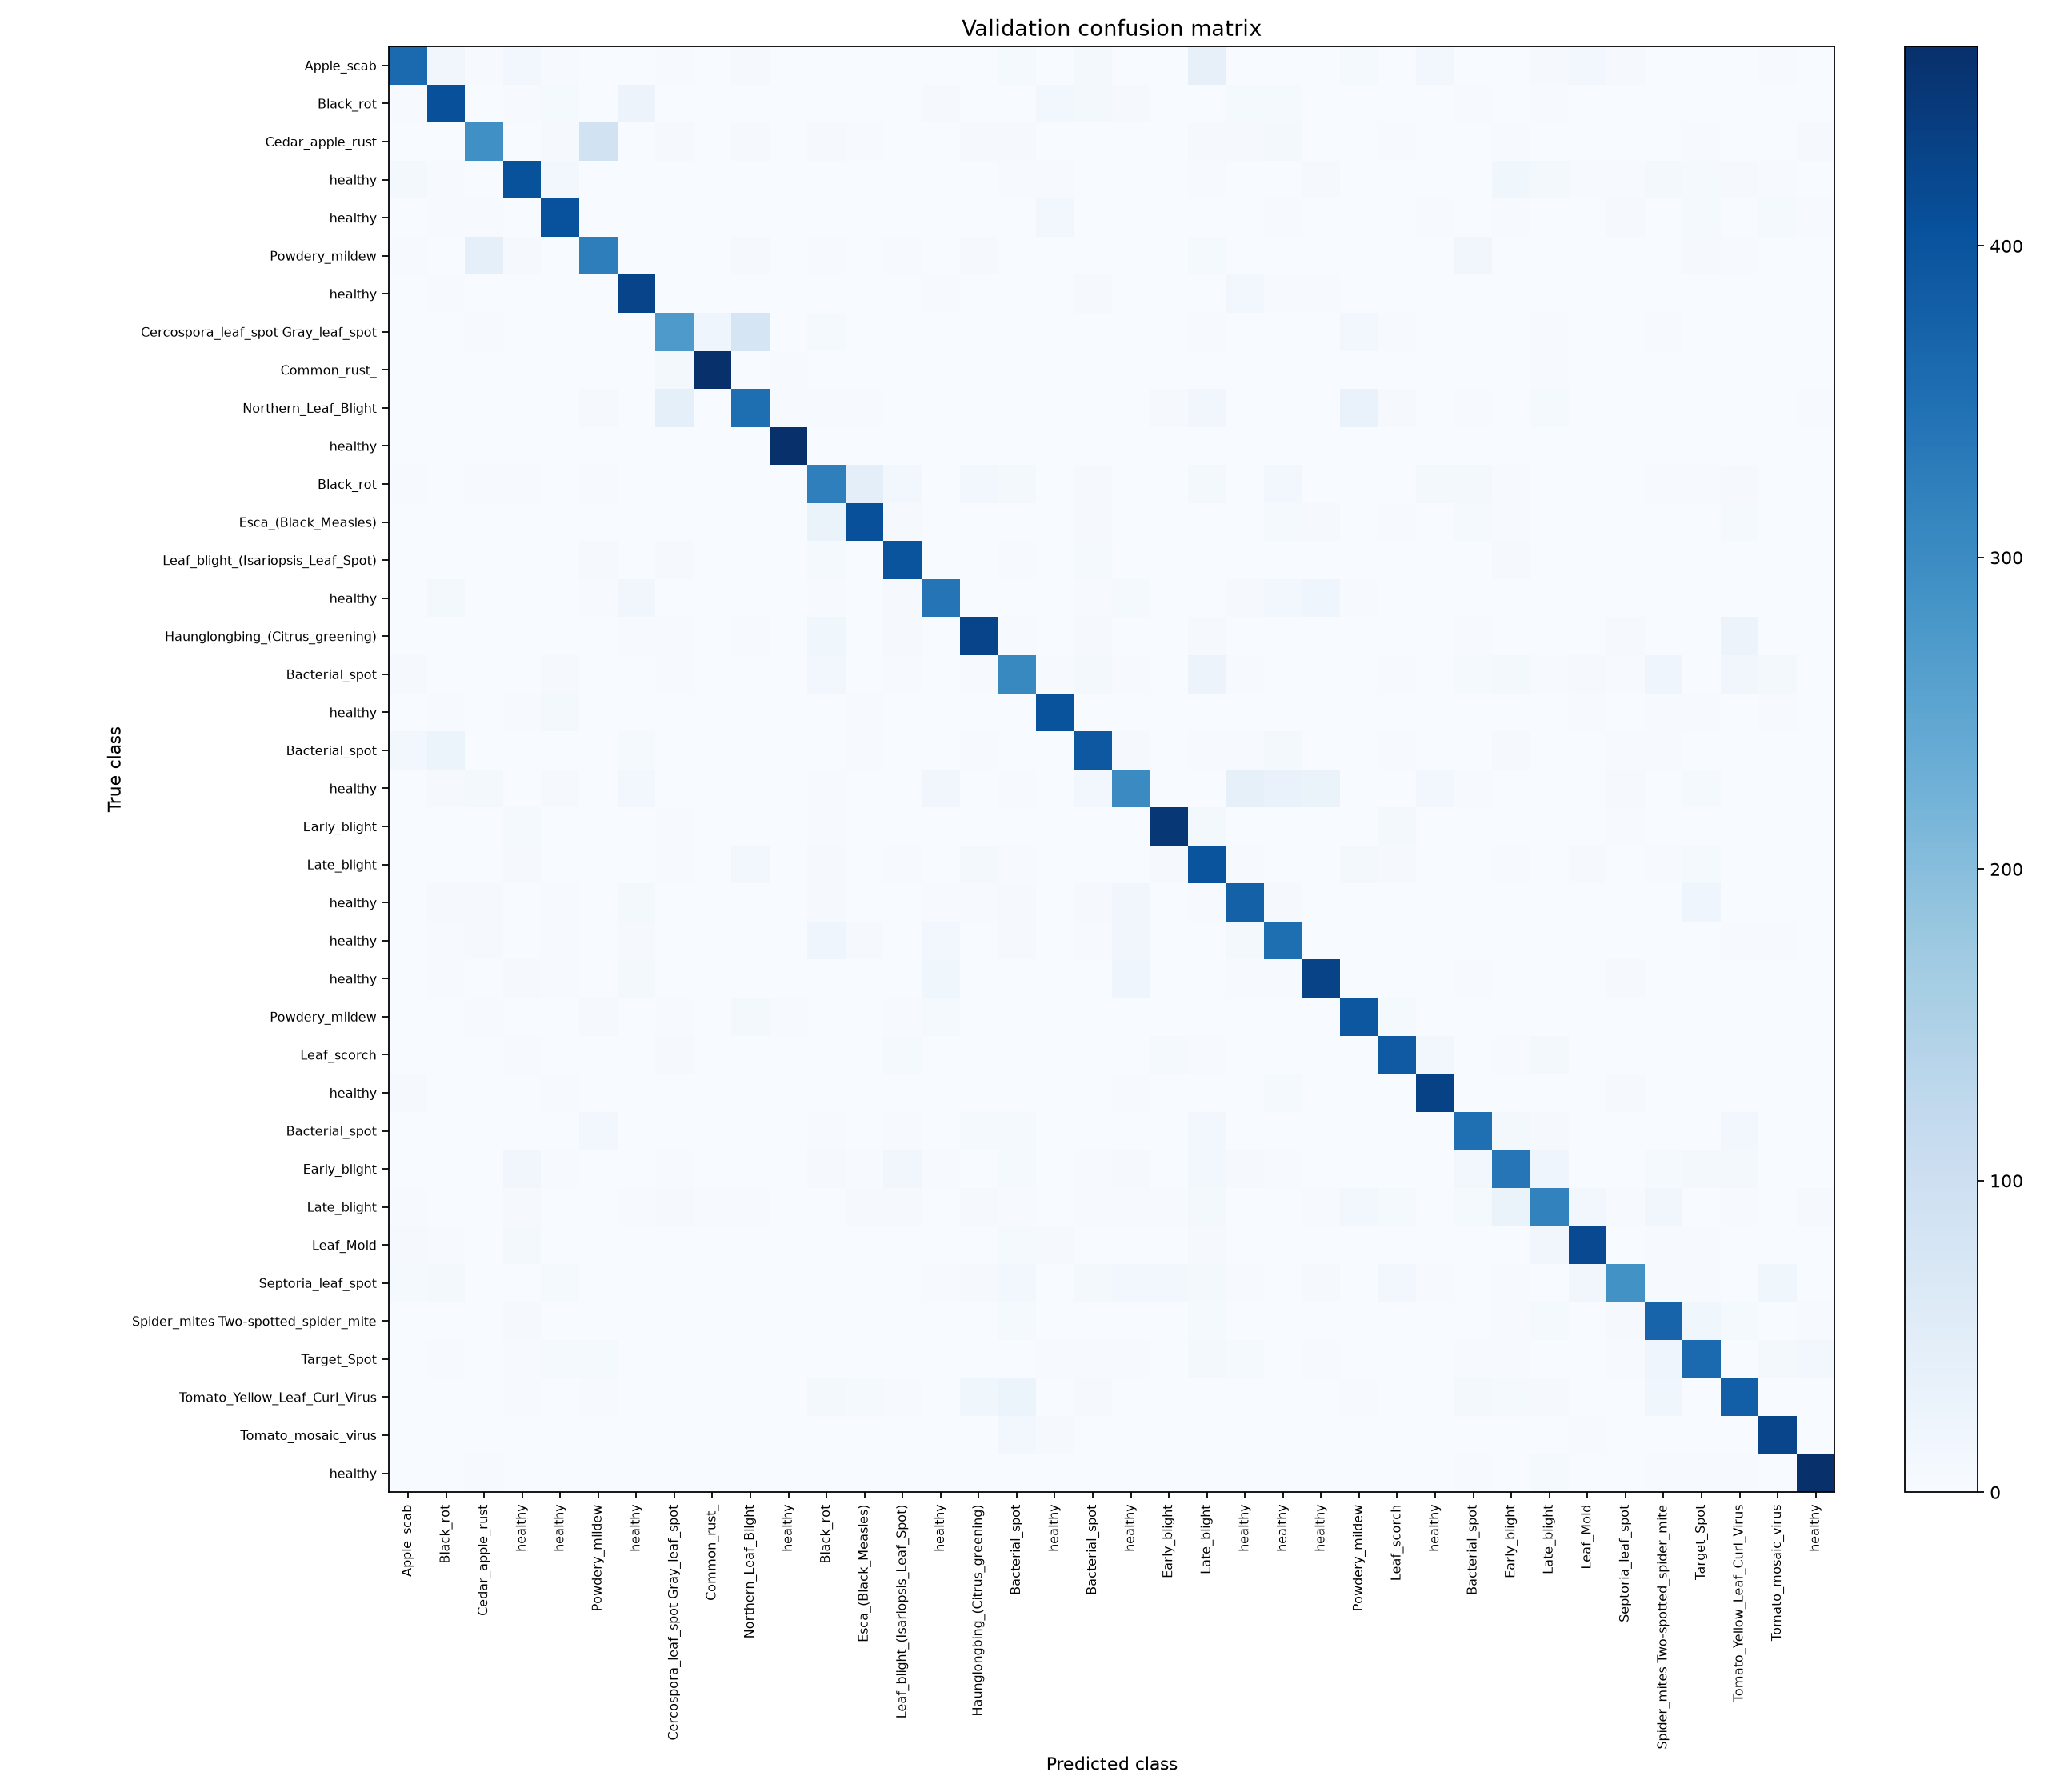

[{'path': 'data/New_Plant_Diseases_Dataset(Augmented)/New Plant Diseases Dataset/valid/Apple___Apple_scab/01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112_270deg.JPG',
  'true_class': 'Apple___Apple_scab',
  'predicted_class': 'Corn_(maize)___healthy',
  'confidence': '0.60141391',
  'correct': 'false'},
 {'path': 'data/New_Plant_Diseases_Dataset(Augmented)/New Plant Diseases Dataset/valid/Apple___Apple_scab/0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Scab 3037_90deg.JPG',
  'true_class': 'Apple___Apple_scab',
  'predicted_class': 'Tomato___Late_blight',
  'confidence': '0.45836905',
  'correct': 'false'},
 {'path': 'data/New_Plant_Diseases_Dataset(Augmented)/New Plant Diseases Dataset/valid/Apple___Apple_scab/03354abb-aa1c-4f9d-a1ef-9f40505cd539___FREC_Scab 3355.JPG',
  'true_class': 'Apple___Apple_scab',
  'predicted_class': 'Squash___Powdery_mildew',
  'confidence': '0.26818380',
  'correct': 'false'},
 {'path': 'data/New_Plant_Diseases_Dataset(Augmented)/New Plant Diseases Dat

In [3]:
import csv
from IPython.display import Image, display

analysis_dir = PROJECT_ROOT / "dataset" / "processed" / "error_analysis"
display(Image(filename=str(analysis_dir / "confusion_matrix.png")))
with (analysis_dir / "validation_errors.csv").open(newline="", encoding="utf-8") as file:
    error_examples = list(csv.DictReader(file))
error_examples[:10]
